In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import tensorflow as tf
print("Devices:", tf.config.list_physical_devices())

Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


2026-10-22 04:20:15.354732: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
import os, re, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
 
import nltk
from nltk.corpus import stopwords
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, roc_auc_score)

In [3]:
SEED = 42
DATA_DIR = os.environ.get('DATA_DIR', '/kaggle/input/datasets/thamidullahkhan/dataset')
MAX_LEN = 60
NUM_WORDS = 50000
EMB_DIM = 100
EPOCHS = int(os.environ.get('EPOCHS', 10))
BATCH_SIZE = 64
USE_PRETRAINED = os.environ.get('USE_PRETRAINED', '1') == '1'
EMB_TRAINABLE = True
RUN_BASELINES = os.environ.get('RUN_BASELINES', '1') == '1'
 
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
 
try:
    nltk.download('stopwords', quiet=True)
    stop_words = set(stopwords.words('english'))
except Exception:
    stop_words = set()
print('stopwords:', len(stop_words))

mental_health_df = pd.read_csv(f'{DATA_DIR}/mental_health.csv')
suicidal_df = pd.read_csv(f'{DATA_DIR}/suicide_dataset.csv', encoding='MacRoman')
depression_df = pd.read_csv(f'{DATA_DIR}/depression_dataset.csv')
 
mental_health_df = mental_health_df.drop(columns=['Unnamed: 0'], errors='ignore')
mental_health_df = mental_health_df.rename(columns={'statement': 'text', 'status': 'label'})
suicidal_df = suicidal_df[['text', 'class']].rename(columns={'class': 'label'})
depression_df = depression_df[['text', 'label']]

stopwords: 198


In [4]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'http\S+|www\.\S+', ' ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    return ' '.join(w for w in t.split() if w not in stop_words)
 
def prepare(df, valid_labels=None):
    df = df.dropna(subset=['text', 'label']).copy()
    if valid_labels is not None:
        df = df[df['label'].isin(valid_labels)]
    df['text'] = df['text'].astype(str).map(clean_text)
    df = df[df['text'].str.len() > 0]
    df = df.drop_duplicates(subset='text', keep='first')
    return df.reset_index(drop=True)
 
def cap_classes(df, caps=None, default=None):
    caps = caps or {}
    parts = []
    for lab, g in df.groupby('label'):
        cap = caps.get(lab, default)
        parts.append(g.sample(n=min(len(g), cap), random_state=SEED) if cap else g)
    return pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
 
depression_df = prepare(depression_df)
suicidal_df = prepare(suicidal_df, ['suicide', 'non-suicide'])
mental_health_df = prepare(mental_health_df,
                           ['Normal', 'Anxiety', 'Bipolar', 'Stress', 'Personality disorder'])
 
depression_df = cap_classes(depression_df, default=6500)
suicidal_df = cap_classes(suicidal_df, default=6500)
mental_health_df = cap_classes(mental_health_df, caps={'Normal': 2718})
 
for name, df in [('depression', depression_df), ('mental_health', mental_health_df), ('suicidal', suicidal_df)]:
    print(name, df.shape, df['label'].value_counts().to_dict())

depression (13000, 2) {0: 6500, 1: 6500}
mental_health (11990, 2) {'Anxiety': 3592, 'Normal': 2718, 'Bipolar': 2501, 'Stress': 2287, 'Personality disorder': 892}
suicidal (13000, 2) {'non-suicide': 6500, 'suicide': 6500}


In [5]:
TASKS = {
    'depression':    dict(df=depression_df,    inp='depression_input',    out='depression_output'),
    'mental_health': dict(df=mental_health_df, inp='mental_health_input', out='mental_health_output'),
    'suicidal':      dict(df=suicidal_df,      inp='suicidal_input',      out='suicidal_output'),
}
HUMAN_NAMES = {
    'depression': ['Non-Depressive', 'Depressive'],
    'mental_health': None, 'suicidal': None,
}
 
for task, cfg in TASKS.items():
    df = cfg['df']
    le = LabelEncoder()
    df['y'] = le.fit_transform(df['label'])
    cfg['encoder'] = le
    cfg['classes'] = [str(c) for c in le.classes_]
    cfg['n_classes'] = len(le.classes_)
    if task == 'depression':
        cfg['classes'] = ['Non-Depressive' if c == '0' else 'Depressive' for c in cfg['classes']]
 
    trainval, test = train_test_split(df, test_size=0.15, stratify=df['y'], random_state=SEED)
    train, val = train_test_split(trainval, test_size=0.15 / 0.85, stratify=trainval['y'], random_state=SEED)
    cfg['train'], cfg['val'], cfg['test'] = train, val, test
    print(f"{task:14s} classes={cfg['classes']}  train/val/test = {len(train)}/{len(val)}/{len(test)}")

depression     classes=['Non-Depressive', 'Depressive']  train/val/test = 9099/1951/1950
mental_health  classes=['Anxiety', 'Bipolar', 'Normal', 'Personality disorder', 'Stress']  train/val/test = 8392/1799/1799
suicidal       classes=['non-suicide', 'suicide']  train/val/test = 9099/1951/1950


In [6]:
tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(pd.concat([c['train']['text'] for c in TASKS.values()]))
VOCAB_SIZE = min(NUM_WORDS, len(tokenizer.word_index) + 1)
print('vocab size:', VOCAB_SIZE)
 
def encode(texts):
    seq = tokenizer.texts_to_sequences(list(texts))
    return pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')
 
for cfg in TASKS.values():
    for split in ('train', 'val', 'test'):
        cfg[f'X_{split}'] = encode(cfg[split]['text'])
        cfg[f'y_{split}'] = cfg[split]['y'].values

vocab size: 50000


In [7]:
def build_embedding_matrix():
    if not USE_PRETRAINED:
        return None
    try:
        import gensim.downloader as api
        wv = api.load('glove-wiki-gigaword-100')
    except Exception as e:
        print('GloVe unavailable, using random embeddings:', repr(e)[:120])
        return None
    matrix = rng.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype('float32')
    matrix[0] = 0.0
    hits = 0
    for word, i in tokenizer.word_index.items():
        if i >= VOCAB_SIZE:
            continue
        if word in wv:
            matrix[i] = wv[word]
            hits += 1
    print(f'GloVe coverage: {hits}/{VOCAB_SIZE - 1} words ({hits / (VOCAB_SIZE - 1):.1%})')
    return matrix
 
EMB_MATRIX = build_embedding_matrix()
 
def make_embedding(mask_zero=True):
    init = keras.initializers.Constant(EMB_MATRIX) if EMB_MATRIX is not None else 'uniform'
    return layers.Embedding(VOCAB_SIZE, EMB_DIM, embeddings_initializer=init,
                            mask_zero=mask_zero, trainable=EMB_TRAINABLE)

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe coverage: 33956/49999 words (67.9%)


In [8]:
@keras.utils.register_keras_serializable(package='mtl')
class AttentionLayer(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True
 
    def build(self, input_shape):
        d = input_shape[-1]
        self.W = self.add_weight(name='W', shape=(d, self.units), initializer='glorot_uniform')
        self.b = self.add_weight(name='b', shape=(self.units,), initializer='zeros')
        self.u = self.add_weight(name='u', shape=(self.units, 1), initializer='glorot_uniform')
 
    def call(self, x, mask=None):
        score = tf.squeeze(tf.matmul(tf.tanh(tf.matmul(x, self.W) + self.b), self.u), axis=-1)
        if mask is not None:
            score = tf.where(mask, score, tf.constant(-1e9, dtype=score.dtype))
        weights = tf.nn.softmax(score, axis=-1)
        return tf.reduce_sum(x * tf.expand_dims(weights, -1), axis=1)
 
    def compute_mask(self, inputs, mask=None):
        return None
 
    def get_config(self):
        cfg = super().get_config()
        cfg.update({'units': self.units})
        return cfg
 
 
def make_shared_encoder():
    inp = keras.Input(shape=(MAX_LEN,))
    x = make_embedding()(inp)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True, dropout=0.2))(x)
    x = AttentionLayer(64)(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, x, name='shared_encoder')
 
 
def build_mtl_model():
    encoder = make_shared_encoder()
    inputs, outputs = {}, {}
    for task, cfg in TASKS.items():
        inp = keras.Input(shape=(MAX_LEN,), name=cfg['inp'])
        h = encoder(inp)
        h = layers.Dense(64, activation='relu', name=f'{task}_dense')(h)
        out = layers.Dense(cfg['n_classes'], activation='softmax', name=cfg['out'])(h)
        inputs[cfg['inp']] = inp; outputs[cfg['out']] = out
    model = keras.Model(inputs, outputs, name='mtl_bilstm_attention')
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss={c['out']: 'sparse_categorical_crossentropy' for c in TASKS.values()},
        metrics={c['out']: 'accuracy' for c in TASKS.values()})
    return model
 
mtl_model = build_mtl_model()
mtl_model.summary()

Model: "mtl_bilstm_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ depression_input    │ (None, 60)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mental_health_input │ (None, 60)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ suicidal_input      │ (None, 60)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_encoder      │ (None, 128)       │  5,092,800 │ depression_input… │
│ (Functional)        │                   │            │ mental_health_in… │
│                     │                   │            │ suicidal_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depression_dense    │ (None, 64)        │      8,256 │ shared_encoder[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mental_health_dense │ (None, 64)        │      8,256 │ shared_encoder[1… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ suicidal_dense      │ (None, 64)        │      8,256 │ shared_encoder[2… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depression_output   │ (None, 2)         │        130 │ depression_dense… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mental_health_outp… │ (None, 5)         │        325 │ mental_health_de… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ suicidal_output     │ (None, 2)         │        130 │ suicidal_dense[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,118,153 (19.52 MB)

 Trainable params: 5,118,153 (19.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
143/143 - 47s - 331ms/step - depression_output_accuracy: 0.8061 - depression_output_loss: 0.4118 - loss: 2.0796 - mental_health_output_accuracy: 0.4906 - mental_health_output_loss: 1.2578 - suicidal_output_accuracy: 0.8167 - suicidal_output_loss: 0.4057 - val_depression_output_accuracy: 0.8790 - val_depression_output_loss: 0.3069 - val_loss: 1.4677 - val_mental_health_output_accuracy: 0.6694 - val_mental_health_output_loss: 0.8763 - val_suicidal_output_accuracy: 0.8811 - val_suicidal_output_loss: 0.2862 - learning_rate: 0.0010
Epoch 2/10
143/143 - 33s - 231ms/step - depression_output_accuracy: 0.8959 - depression_output_loss: 0.2551 - loss: 1.3243 - mental_health_output_accuracy: 0.7213 - mental_health_output_loss: 0.8055 - suicidal_output_accuracy: 0.9001 - suicidal_output_loss: 0.2606 - val_depression_output_accuracy: 0.9113 - val_depression_output_loss: 0.2429 - val_loss: 1.2241 - val_mental_health_output_accuracy: 0.7365 - val_mental_health_output_loss: 0.7538 - val_suic

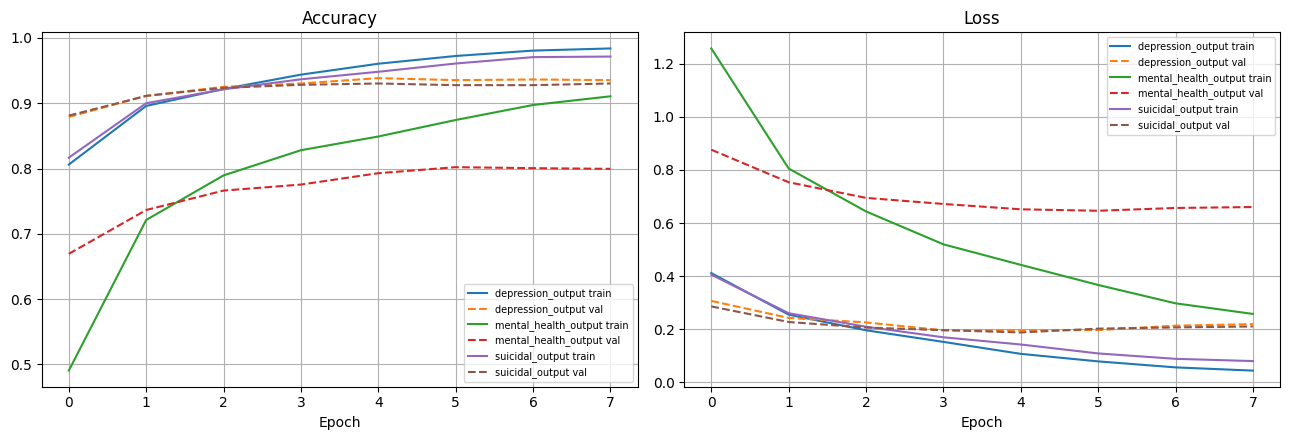

In [9]:
def resample_to(X, y, n):
    idx = np.arange(len(X))
    if len(X) < n:
        idx = np.concatenate([idx, rng.choice(len(X), n - len(X), replace=True)])
    rng.shuffle(idx)
    return X[idx], y[idx]
 
def aligned(split):
    n = max(len(c[f'X_{split}']) for c in TASKS.values())
    xs, ys = {}, {}
    for cfg in TASKS.values():
        xs[cfg['inp']], ys[cfg['out']] = resample_to(cfg[f'X_{split}'], cfg[f'y_{split}'], n)
    return xs, ys
 
x_train, y_train = aligned('train')
x_val, y_val = aligned('val')
sw_train = {k: compute_sample_weight('balanced', v) for k, v in y_train.items()}
 
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
]
 
history = mtl_model.fit(x_train, y_train, sample_weight=sw_train,
                        validation_data=(x_val, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=2)
 

def plot_history(h):
    hist = h.history
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for cfg in TASKS.values():
        o = cfg['out']
        ax[0].plot(hist[f'{o}_accuracy'], label=f'{o} train')
        ax[0].plot(hist[f'val_{o}_accuracy'], '--', label=f'{o} val')
        ax[1].plot(hist[f'{o}_loss'], label=f'{o} train')
        ax[1].plot(hist[f'val_{o}_loss'], '--', label=f'{o} val')
    ax[0].set_title('Accuracy'); ax[1].set_title('Loss')
    for a in ax:
        a.set_xlabel('Epoch'); a.grid(True); a.legend(fontsize=7)
    plt.tight_layout(); plt.show()
 
plot_history(history)


=== depression (TEST, n=1950) ===
                precision    recall  f1-score   support

Non-Depressive      0.950     0.912     0.930       975
    Depressive      0.915     0.952     0.933       975

      accuracy                          0.932      1950
     macro avg      0.932     0.932     0.932      1950
  weighted avg      0.932     0.932     0.932      1950


=== mental_health (TEST, n=1799) ===
                      precision    recall  f1-score   support

             Anxiety      0.888     0.837     0.862       539
             Bipolar      0.856     0.843     0.849       375
              Normal      0.917     0.863     0.889       408
Personality disorder      0.496     0.828     0.620       134
              Stress      0.723     0.662     0.691       343

            accuracy                          0.810      1799
           macro avg      0.776     0.806     0.782      1799
        weighted avg      0.827     0.810     0.815      1799


=== suicidal (TEST, n=1950

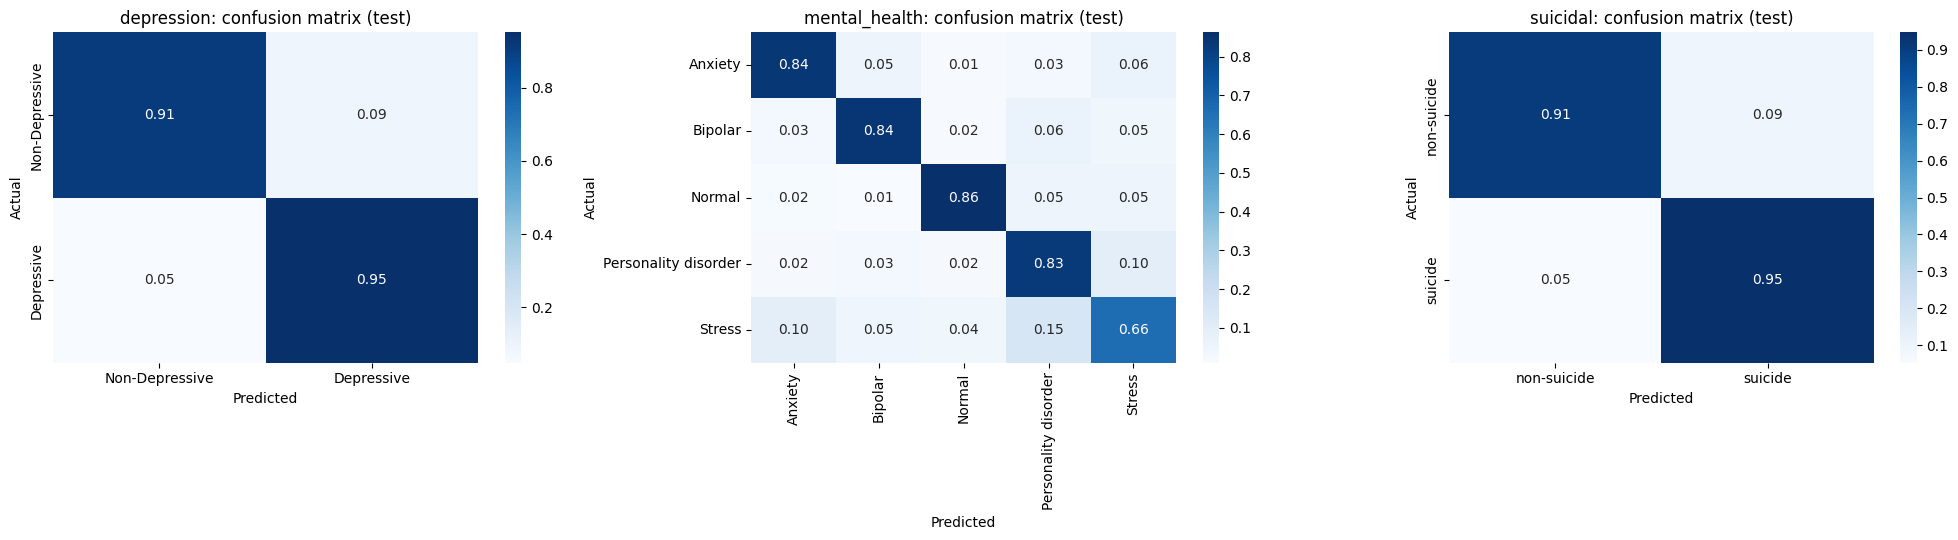

In [10]:
OUT_INDEX = {cfg['out']: i for i, cfg in enumerate(TASKS.values())}
 
def mtl_predict_proba(model, task, X):
    out = model.predict({c['inp']: X for c in TASKS.values()}, batch_size=256, verbose=0)
    name = TASKS[task]['out']
    return out[name] if isinstance(out, dict) else out[OUT_INDEX[name]]
 
def auc_ovr(y_true, proba):
    try:
        if proba.shape[1] == 2:
            return roc_auc_score(y_true, proba[:, 1])
        return roc_auc_score(y_true, proba, multi_class='ovr', average='macro')
    except ValueError:
        return float('nan')
 
mtl_results, mtl_test_pred = {}, {}
for task, cfg in TASKS.items():
    proba = mtl_predict_proba(mtl_model, task, cfg['X_test'])
    pred = proba.argmax(1)
    mtl_test_pred[task] = pred
    mtl_results[task] = dict(accuracy=accuracy_score(cfg['y_test'], pred),
                             macro_f1=f1_score(cfg['y_test'], pred, average='macro'),
                             auc_roc=auc_ovr(cfg['y_test'], proba))
    print(f'\n=== {task} (TEST, n={len(pred)}) ===')
    print(classification_report(cfg['y_test'], pred, target_names=cfg['classes'], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (task, cfg) in zip(axes, TASKS.items()):
    cm = confusion_matrix(cfg['y_test'], mtl_test_pred[task], normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=cfg['classes'],
                yticklabels=cfg['classes'], ax=ax)
    ax.set_title(f'{task}: confusion matrix (test)')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

depression     rnn                acc=0.881  macro-F1=0.881
depression     cnn                acc=0.891  macro-F1=0.891


depression     lstm               acc=0.910  macro-F1=0.910


depression     bilstm_attention   acc=0.918  macro-F1=0.918
mental_health  rnn                acc=0.681  macro-F1=0.631
mental_health  cnn                acc=0.810  macro-F1=0.783
mental_health  lstm               acc=0.833  macro-F1=0.808
mental_health  bilstm_attention   acc=0.840  macro-F1=0.816
suicidal       rnn                acc=0.863  macro-F1=0.863
suicidal       cnn                acc=0.897  macro-F1=0.897
suicidal       lstm               acc=0.916  macro-F1=0.916
suicidal       bilstm_attention   acc=0.909  macro-F1=0.909

Macro-F1 on the held-out test set:
task                  depression  mental_health  suicidal
model                                                    
MTL BiLSTM+Attention       0.932          0.782     0.928
STL bilstm_attention       0.918          0.816     0.909
STL cnn                    0.891          0.783     0.897
STL lstm                   0.910          0.808     0.916
STL rnn                    0.881          0.631     0.863


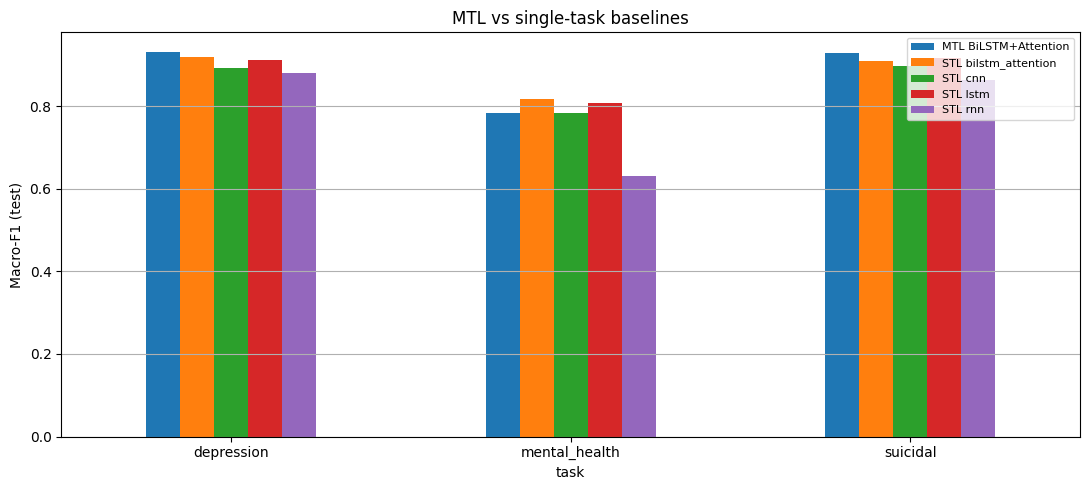

In [11]:
def build_baseline(kind, n_classes):
    inp = keras.Input(shape=(MAX_LEN,))
    x = make_embedding(mask_zero=(kind != 'cnn'))(inp)
    if kind == 'rnn':
        x = layers.SimpleRNN(64)(x)
    elif kind == 'lstm':
        x = layers.LSTM(64, dropout=0.2)(x)
    elif kind == 'cnn':
        x = layers.Conv1D(64, 5, activation='relu')(x)
        x = layers.GlobalMaxPooling1D()(x)
    elif kind == 'bilstm_attention':
        x = layers.Bidirectional(layers.LSTM(64, return_sequences=True, dropout=0.2))(x)
        x = AttentionLayer(64)(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    m = keras.Model(inp, out, name=f'stl_{kind}')
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m
 
rows = []
for task, r in mtl_results.items():
    rows.append(dict(task=task, model='MTL BiLSTM+Attention', **r))
 
if RUN_BASELINES:
    for task, cfg in TASKS.items():
        sw = compute_sample_weight('balanced', cfg['y_train'])
        for kind in ['rnn', 'cnn', 'lstm', 'bilstm_attention']:
            keras.utils.set_random_seed(SEED)
            m = build_baseline(kind, cfg['n_classes'])
            m.fit(cfg['X_train'], cfg['y_train'], sample_weight=sw,
                  validation_data=(cfg['X_val'], cfg['y_val']),
                  epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0,
                  callbacks=[keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1, min_lr=1e-5),
                             keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
            proba = m.predict(cfg['X_test'], batch_size=256, verbose=0)
            pred = proba.argmax(1)
            rows.append(dict(task=task, model=f'STL {kind}',
                             accuracy=accuracy_score(cfg['y_test'], pred),
                             macro_f1=f1_score(cfg['y_test'], pred, average='macro'),
                             auc_roc=auc_ovr(cfg['y_test'], proba)))
            print(f'{task:14s} {kind:18s} acc={rows[-1]["accuracy"]:.3f}  macro-F1={rows[-1]["macro_f1"]:.3f}')
 
results_df = pd.DataFrame(rows)
results_df.to_csv('results_table.csv', index=False)
display_df = results_df.pivot(index='model', columns='task', values='macro_f1').round(3)
print('\nMacro-F1 on the held-out test set:')
print(display_df)

results_df.pivot(index='task', columns='model', values='macro_f1').plot(kind='bar', figsize=(11, 5))
plt.ylabel('Macro-F1 (test)'); plt.title('MTL vs single-task baselines'); plt.xticks(rotation=0)
plt.legend(fontsize=8); plt.grid(axis='y'); plt.tight_layout(); plt.show()

In [12]:
for task, cfg in TASKS.items():
    proba = mtl_predict_proba(mtl_model, task, cfg['X_test'])
    auc = auc_ovr(cfg['y_test'], proba)

    print(f"{task}: AUC = {auc:.4f}")

depression: AUC = 0.9792
mental_health: AUC = 0.9565
suicidal: AUC = 0.9764


In [13]:
mtl_model.save('mtl_bilstm_attention.keras')
with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)
print('saved model + tokenizer')

saved model + tokenizer


In [14]:
def classify_text(text):
    seq = encode([clean_text(text)])
    out = mtl_model.predict({c['inp']: seq for c in TASKS.values()}, verbose=0)
    result = {}
    for task, cfg in TASKS.items():
        p = out[cfg['out']] if isinstance(out, dict) else out[OUT_INDEX[cfg['out']]]
        i = int(p[0].argmax())
        result[task] = (cfg['classes'][i], float(p[0][i]))
    return result
 
print(classify_text('I feel so anxious and cannot sleep, my mind keeps racing'))

try:
    import ipywidgets as widgets
    from IPython.display import display
    box = widgets.Text(description='Input text:', placeholder='Enter your text', layout=widgets.Layout(width='600px'))
    btn = widgets.Button(description='Classify')
    area = widgets.Output()
 
    def _click(_):
        with area:
            area.clear_output()
            for task, (label, conf) in classify_text(box.value).items():
                print(f'{task:14s}: {label}  ({conf:.2f})')
 
    btn.on_click(_click)
    display(box, btn, area)
except ImportError:
    pass

{'depression': ('Depressive', 0.7952971458435059), 'mental_health': ('Anxiety', 0.9081171751022339), 'suicidal': ('suicide', 0.7803847789764404)}


Text(value='', description='Input text:', layout=Layout(width='600px'), placeholder='Enter your text')

Button(description='Classify', style=ButtonStyle())

Output()